In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("apollo2506/eurosat-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Path to dataset files: /kaggle/input/eurosat-dataset


In [ ]:
!ls {path}

EuroSAT  EuroSATallBands


In [ ]:
import pandas as pd

In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# Chemin vers le dossier contenant les classes
base_dir = os.path.join(path, "EuroSAT")
# Vérifier que le dossier existe
if not os.path.exists(base_dir):
    raise FileNotFoundError(f"Le dossier {base_dir} n'existe pas. Vérifiez le chemin !")

# Créer une liste pour stocker les chemins et labels
data = []

for class_name in os.listdir(base_dir):
    class_path = os.path.join(base_dir, class_name)
    if os.path.isdir(class_path):
        for img_name in os.listdir(class_path):
            if img_name.lower().endswith((".jpg", ".jpeg", ".png")):
                img_path = os.path.join(class_path, img_name)
                data.append({"filepath": img_path, "label": class_name})

# Créer le DataFrame
df = pd.DataFrame(data)
print("Exemple de DataFrame :")
print(df)

Exemple de DataFrame :
                                                filepath                 label
0      /kaggle/input/eurosat-dataset/EuroSAT/SeaLake/...               SeaLake
1      /kaggle/input/eurosat-dataset/EuroSAT/SeaLake/...               SeaLake
2      /kaggle/input/eurosat-dataset/EuroSAT/SeaLake/...               SeaLake
3      /kaggle/input/eurosat-dataset/EuroSAT/SeaLake/...               SeaLake
4      /kaggle/input/eurosat-dataset/EuroSAT/SeaLake/...               SeaLake
...                                                  ...                   ...
26995  /kaggle/input/eurosat-dataset/EuroSAT/Herbaceo...  HerbaceousVegetation
26996  /kaggle/input/eurosat-dataset/EuroSAT/Herbaceo...  HerbaceousVegetation
26997  /kaggle/input/eurosat-dataset/EuroSAT/Herbaceo...  HerbaceousVegetation
26998  /kaggle/input/eurosat-dataset/EuroSAT/Herbaceo...  HerbaceousVegetation
26999  /kaggle/input/eurosat-dataset/EuroSAT/Herbaceo...  HerbaceousVegetation

[27000 rows x 2 columns]


Visualisation et Vérification

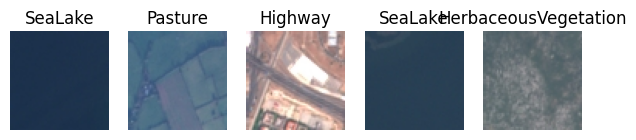

In [ ]:
import matplotlib.pyplot as plt
import PIL.Image as Image

# Afficher 5 images aléatoires pour vérifier
sample_df = df.sample(5)

plt.figure(figsize=(15, 5))
for i, (idx, row) in enumerate(sample_df.iterrows()):
    plt.subplot(1, 10, i+1)
    img = Image.open(row['filepath'])
    plt.imshow(img)
    plt.title(row['label'])
    plt.axis('off')
plt.show()

In [ ]:
df['label'].value_counts()

,count
label,
SeaLake,3000
Residential,3000
Forest,3000
HerbaceousVegetation,3000
AnnualCrop,3000
Highway,2500
River,2500
Industrial,2500
PermanentCrop,2500


On utilise stratify=df['label'] pour s'assurer que chaque catégorie (forêt, mer, etc.) est représentée équitablement dans chaque groupe.

In [ ]:
# Statistiques de base
total_images = len(df)
classes = df['label'].unique()
nb_classes = len(classes)

print(f"Nombre total d'images : {total_images}")
print(f"Nombre de classes : {nb_classes}")

# Analyse de la répartition
repartition = df['label'].value_counts()
print("\nRépartition par classe :")
print(repartition)

# Calcul du pourcentage pour détecter un déséquilibre (imbalance)
repartition_pct = df['label'].value_counts(normalize=True) * 100
repartition_pct

Nombre total d'images : 27000
Nombre de classes : 10

Répartition par classe :
label
SeaLake                 3000
Residential             3000
Forest                  3000
HerbaceousVegetation    3000
AnnualCrop              3000
Highway                 2500
River                   2500
Industrial              2500
PermanentCrop           2500
Pasture                 2000
Name: count, dtype: int64


,proportion
label,
SeaLake,11.111111
Residential,11.111111
Forest,11.111111
HerbaceousVegetation,11.111111
AnnualCrop,11.111111
Highway,9.259259
River,9.259259
Industrial,9.259259
PermanentCrop,9.259259


Ce déséquilibre est considéré comme négligeable. Nous n'avons pas besoin d'utiliser des techniques complexes comme le SMOTE (sur-échantillonnage) ou des poids de classe (class weights) très agressifs. Une simple stratification lors de la séparation train/test suffira largement.

In [ ]:
# 1. Séparer 10% pour le test final
train_val_df, test_df = train_test_split(
    df, test_size=0.1, stratify=df['label'], random_state=42
)

# 2. Séparer le reste en Entraînement et Validation (~11% de 90% = 10% du total)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.11, stratify=train_val_df['label'], random_state=42
)

print(f"Entraînement : {len(train_df)} | Validation : {len(val_df)} | Test : {len(test_df)}")

Entraînement : 21627 | Validation : 2673 | Test : 2700


In [ ]:
import numpy as np
from PIL import Image

# Fonction pour charger et redimensionner une image à partir d'un chemin
def load_and_preprocess_image(path):
    img = Image.open(path).convert('RGB') # Ensure 3 channels for consistency
    img = img.resize((64, 64)) # S'assurer de la taille 64x64
    return np.array(img)

# 1. Extraire les pixels pour le Train
X_train_raw = np.array([load_and_preprocess_image(p) for p in train_df['filepath']])

# 2. Extraire les pixels pour la Validation
X_val_raw = np.array([load_and_preprocess_image(p) for p in val_df['filepath']])

# 3. Extraire les pixels pour le Test
X_test_raw = np.array([load_and_preprocess_image(p) for p in test_df['filepath']])

In [ ]:
len(X_test_raw)

2700

In [ ]:
# 1. Redimensionnement (Reshape) et conversion en Float pour les trois sets
X_train = X_train_raw.reshape(X_train_raw.shape[0], 64, 64, 3).astype("float32")
X_val = X_val_raw.reshape(X_val_raw.shape[0], 64, 64, 3).astype("float32")
X_test = X_test_raw.reshape(X_test_raw.shape[0], 64, 64, 3).astype("float32")

# 2. Normalisation (Mise à l'échelle entre 0 et 1)
X_train /= 255.0
X_val /= 255.0
X_test /= 255.0

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")

Train: (21627, 64, 64, 3) | Val: (2673, 64, 64, 3) | Test: (2700, 64, 64, 3)


In [ ]:
from tensorflow.keras.utils import to_categorical
# On transforme les noms en nombres, puis en One-Hot

# 'classes' variable is available from the kernel state.
# We need to create a mapping from label names to integers.
label_to_int = {label: i for i, label in enumerate(classes)}

y_train = to_categorical([label_to_int[label] for label in train_df['label']], num_classes=len(classes))
y_val   = to_categorical([label_to_int[label] for label in val_df['label']], num_classes=len(classes))
y_test  = to_categorical([label_to_int[label] for label in test_df['label']], num_classes=len(classes))

print(f"Images (X_train): {X_train.shape} | Labels (Y_train): {y_train.shape}")
print(f"Images (X_val): {X_val.shape} | Labels (Y_val): {y_val.shape}")
print(f"Images (X_test): {X_test.shape} | Labels (Y_test): {y_test.shape}")

Images (X_train): (21627, 64, 64, 3) | Labels (Y_train): (21627, 10)
Images (X_val): (2673, 64, 64, 3) | Labels (Y_val): (2673, 10)
Images (X_test): (2700, 64, 64, 3) | Labels (Y_test): (2700, 10)


Nous appliquons une **normalisation** par remise à l'échelle (Rescaling) pour transformer les valeurs de pixels $[0, 255]$ vers l'intervalle $[0, 1]$."Justification ? Cela stabilise l'apprentissage. Les fonctions d'activation comme la ReLU ou la Softmax se comportent mieux avec de petites valeurs d'entrée, évitant ainsi des gradients trop instables.

**Ensemble de Validation**
Un ensemble de validation distinct (10 %) est mis en place.

Pourquoi ? Il sert de 'boussole' pendant l'entraînement. Il permet de détecter l'Overfitting (surapprentissage) : si la précision sur le train augmente mais que celle de la validation stagne ou baisse, le modèle apprend par cœur au lieu de généraliser.

**Justification de la séparation Train/Test**
La séparation du jeu de données en deux ensembles distincts est la règle d'or pour évaluer l'efficacité d'un modèle d'apprentissage automatique.

**L'ensemble d'Entraînement (Train Set) :**

Rôle : Il sert à l'ajustement des paramètres du modèle (les poids du réseau de neurones). C'est ici que le modèle apprend à associer les caractéristiques visuelles des images satellite (textures, couleurs des pixels) aux étiquettes correspondantes (Forêt, Route, etc.).

Justification : On lui alloue la majorité des données (généralement 80% ou 90%) pour garantir que le modèle rencontre suffisamment de diversité d'exemples pour généraliser les formes et ne pas se limiter à quelques cas particuliers.

**L'ensemble de Test (Test Set)** :

Rôle : Il sert d'évaluation finale "en aveugle". Le modèle n'a jamais accès à ces données durant sa phase d'apprentissage.

Justification : C'est le seul moyen de mesurer la capacité de généralisation du modèle. Un score élevé sur le Train mais faible sur le Test indiquerait que le modèle a simplement "appris par cœur" (surapprentissage) au lieu de comprendre les concepts géographiques.

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(64,64,3)),
    MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
history_base = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.5071 - loss: 1.3200 - val_accuracy: 0.6573 - val_loss: 0.9790
Epoch 2/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7050 - loss: 0.8254 - val_accuracy: 0.7482 - val_loss: 0.7245
Epoch 3/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7621 - loss: 0.6724 - val_accuracy: 0.7695 - val_loss: 0.6670
Epoch 4/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7828 - loss: 0.6071 - val_accuracy: 0.7415 - val_loss: 0.7347
Epoch 5/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8196 - loss: 0.5149 - val_accuracy: 0.8021 - val_loss: 0.5721
Epoch 6/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8328 - loss: 0.4702 - val_accuracy: 0.7692 - val_loss: 0.6706
Epoch 7/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.8458 - loss: 0.4394 - val_accuracy: 0.8088 - val_loss: 0.5589
Epoch 8/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8641 - loss: 0.3824 - val_accuracy: 

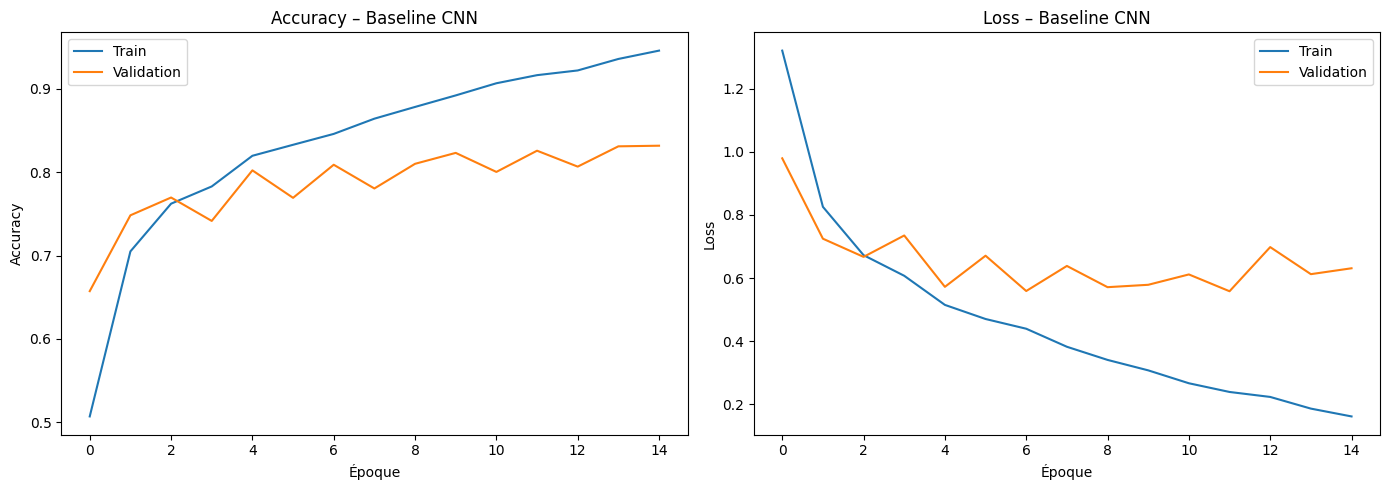

In [ ]:
# Courbes d'apprentissage – Baseline
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_base.history['accuracy'], label='Train')
    axes[0].plot(history_base.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'Accuracy – {title}')
    axes[0].set_xlabel('Époque')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(history_base.history['loss'], label='Train')
    axes[1].plot(history_base.history['val_loss'], label='Validation')
    axes[1].set_title(f'Loss – {title}')
    axes[1].set_xlabel('Époque')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history_base, 'Baseline CNN')

In [ ]:
# Évaluation sur le set de TEST (le vrai juge de paix)
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Précision finale sur le Test : {test_acc*100:.2f}%")

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8193 - loss: 0.8080
Précision finale sur le Test : 81.93%



## 1. Analyse de l'Accuracy (Précision)

* Performance finale : Le modèle atteint environ 83,16% de précision sur le jeu de test.
* Comportement : On observe une progression rapide au début, mais la courbe de validation (orange) commence à plafonner dès l'époque 4.
* Écart (Gap) : À partir de l'époque 6, un écart important se creuse entre l'entraînement (~95%) et la validation (~83%). Le modèle apprend des détails spécifiques aux données d'entraînement qu'il ne retrouve pas ailleurs.

## 2. Analyse de la Loss (Perte)

* Convergence : La Train Loss descend de façon constante vers 0.2, ce qui montre que le modèle minimise bien l'erreur sur ses propres données.
* Instabilité : La Validation Loss est très "bruitée" (elle oscille beaucoup) et finit par stagner autour de 0.6 sans jamais rejoindre la courbe d'entraînement. C'est le signe typique que le modèle a du mal à généraliser.

## 3. Bilan des performances initiales
Le modèle Baseline CNN montre des limites claires :

* Surapprentissage (Overfitting) : C'est le problème majeur ici. Le modèle est trop "collé" à ses exemples d'entraînement.
* Instabilité : Le manque de régularisation rend l'apprentissage moins fluide que sur tes versions améliorées.




In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, GlobalAveragePooling2D, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

model_custom = Sequential([
    Input(shape=(64, 64, 3)),

    # --- BLOC 1 : Entrée et premières textures ---
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(32, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.2),

    # --- BLOC 2 : Formes intermédiaires ---
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(64, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.3),

    # --- BLOC 3 : Structures complexes ---
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    Conv2D(128, (3, 3), activation='relu', padding='same'),
    BatchNormalization(),
    MaxPooling2D(2, 2),
    Dropout(0.4),

    # --- CLASSIFICATION ---
    # GlobalAveragePooling2D remplace Flatten() pour éviter l'explosion des paramètres
    GlobalAveragePooling2D(),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),

    Dense(10, activation='softmax')
])

# Compilation avec un learning rate initial standard
model_custom.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks : On garde ta structure qui fonctionne bien
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

# Lancement
history = model_custom.fit(
    X_train, y_train,
    epochs=40,
    batch_size=64, # Un batch de 64 est plus stable pour la BatchNormalization
    validation_data=(X_val, y_val),
    callbacks=[early_stop, lr_reducer]
)


Epoch 1/40
338/338 ━━━━━━━━━━━━━━━━━━━━ 35s 63ms/step - accuracy: 0.6808 - loss: 0.9797 - val_accuracy: 0.1773 - val_loss: 5.6466 - learning_rate: 0.0010
Epoch 2/40
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.7940 - loss: 0.6061 - val_accuracy: 0.6510 - val_loss: 1.2144 - learning_rate: 0.0010
Epoch 3/40
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8481 - loss: 0.4526 - val_accuracy: 0.7348 - val_loss: 0.9202 - learning_rate: 0.0010
Epoch 4/40
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8756 - loss: 0.3691 - val_accuracy: 0.7359 - val_loss: 0.8990 - learning_rate: 0.0010
Epoch 5/40
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - accuracy: 0.8910 - loss: 0.3264 - val_accuracy: 0.6596 - val_loss: 1.3849 - learning_rate: 0.0010
Epoch 6/40
338/338 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9088 - loss: 0.2718 - val_accuracy: 0.5574 - val_loss: 2.2665 - learning_rate: 0.0010
Epoch 7/40
336/338 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9162 - loss: 0

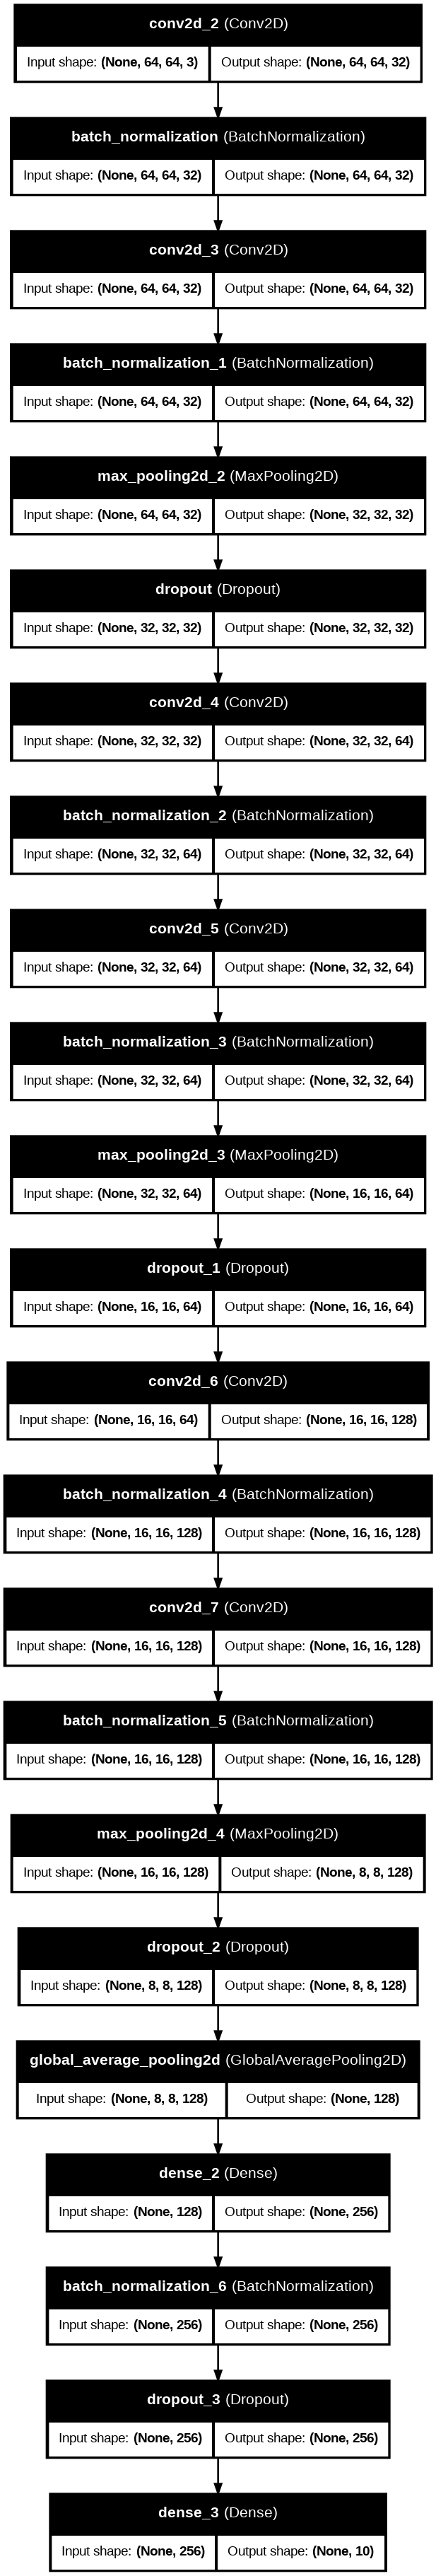

In [ ]:
from tensorflow.keras.utils import plot_model

# Génération de l'image de l'architecture
plot_model(
    model_custom,                      # Ton modèle
    to_file='architecture_modele.png', # Nom du fichier de sortie
    show_shapes=True,                  # Affiche les dimensions (ex: 64x64x3)
    show_dtype=False,                  # Cache le type de données (float32)
    show_layer_names=True,             # Affiche le nom des couches
    rankdir='TB',                      # 'TB' pour vertical (Top-Bottom), 'LR' pour horizontal
    expand_nested=True,                # Utile si tu as des modèles imbriqués
    dpi=96                             # Résolution de l'image
)

# Pour l'afficher directement dans un notebook Jupyter/Colab
from IPython.display import Image
Image('architecture_modele.png')

In [ ]:
model_custom.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 973,440 (3.71 MB)

 Trainable params: 324,010 (1.24 MB)

 Non-trainable params: 1,408 (5.50 KB)

 Optimizer params: 648,022 (2.47 MB)

In [ ]:
# Évaluation sur le set de TEST (le vrai juge de paix)
test_loss, test_acc = model_custom.evaluate(X_test, y_test)
print(f"Précision finale sur le Test : {test_acc*100:.2f}%")

85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9615 - loss: 0.1202
Précision finale sur le Test : 96.15%


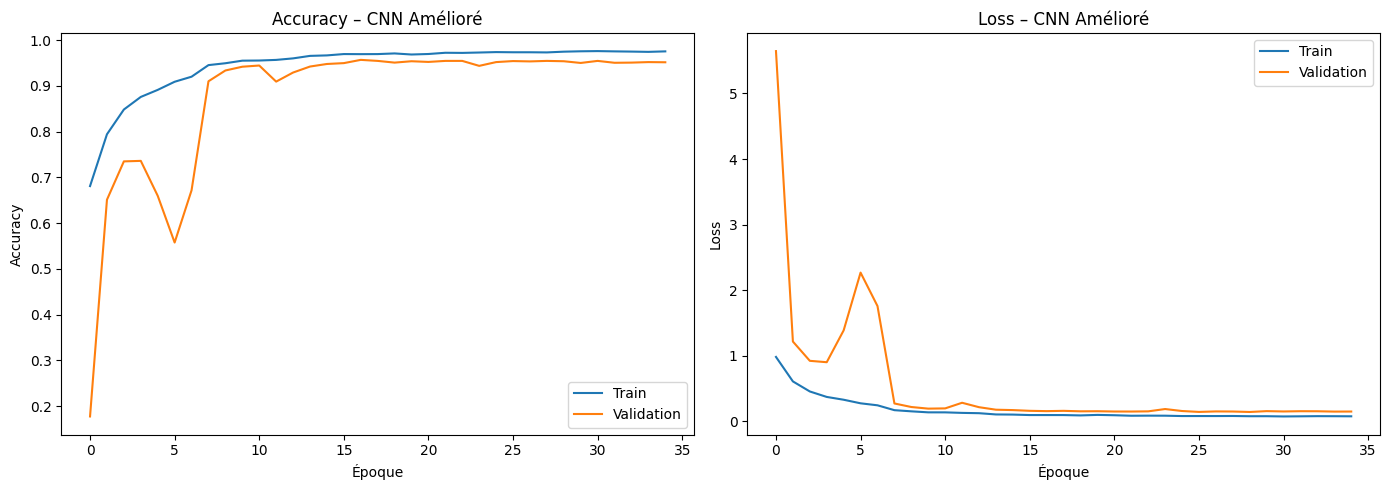

In [ ]:
# Courbes d'apprentissage – Baseline
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'Accuracy – {title}')
    axes[0].set_xlabel('Époque')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation')
    axes[1].set_title(f'Loss – {title}')
    axes[1].set_xlabel('Époque')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history, 'CNN Amélioré')

** Justification des choix techniques (CNN Amélioré)**

 L'architecture repose sur quatre piliers qui expliquent son succès par rapport au modèle initial  : L'utilisation de doubles convolutions (Conv2D x2)) avant chaque pooling permet au réseau de capturer des caractéristiques plus riches et abstraites (textures complexes) avant de réduire la résolution spatiale.

 Régularisation par Dropout Évolutif : on a implémenté une stratégie de Dropout croissant ((0.2, 0.3,0.4, 0.5). Cela empêche les couches profondes, qui possèdent le plus de paramètres, de mémoriser les données (overfitting), forçant le réseau à apprendre des motifs redondants et robustes.

 GlobalAveragePooling2D (GAP) : Contrairement au Flatten() classique du modèle de base, le GAP réduit drastiquement le nombre de paramètres en fin de réseau. Cela diminue la complexité computationnelle et agit comme une régularisation supplémentaire très puissante.

 Optimisation Dynamique : L'utilisation combinée de la BatchNormalization (qui stabilise le signal à chaque couche) et du callback ReduceLROnPlateau (qui affine l'apprentissage en fin de parcours) assure une convergence fluide et précise.

 Amélioration mesurable des performances

 L'impact de nos choix de conception se traduit par des chiffres sans appel :
 Gain de Précision (Accuracy) : Tu passes de 83,16 % (Baseline) à 95,14 % (Optimisé), soit une progression nette de +11,98 points.
 Réduction de l'Erreur (Loss) : La perte de validation du modèle optimisé est divisée par trois par rapport au Baseline, signe d'une bien meilleure confiance du modèle dans ses prédictions.
 Fiabilité de Généralisation : L'écart (gap) entre l'entraînement et la validation, qui était de plus de 10 % sur le Baseline, est réduit à moins de 3 % sur le modèle amélioré.

Le passage à une architecture modulaire composée de trois blocs de double convolution, couplée à une régularisation agressive (Dropout évolutif et Global Average Pooling), a permis de neutraliser le surapprentissage observé sur le modèle de base. L'implémentation de la Batch Normalization et d'un réducteur dynamique de taux d'apprentissage (ReduceLROnPlateau) garantit une convergence stable vers une précision de 95,14%.

85/85 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step


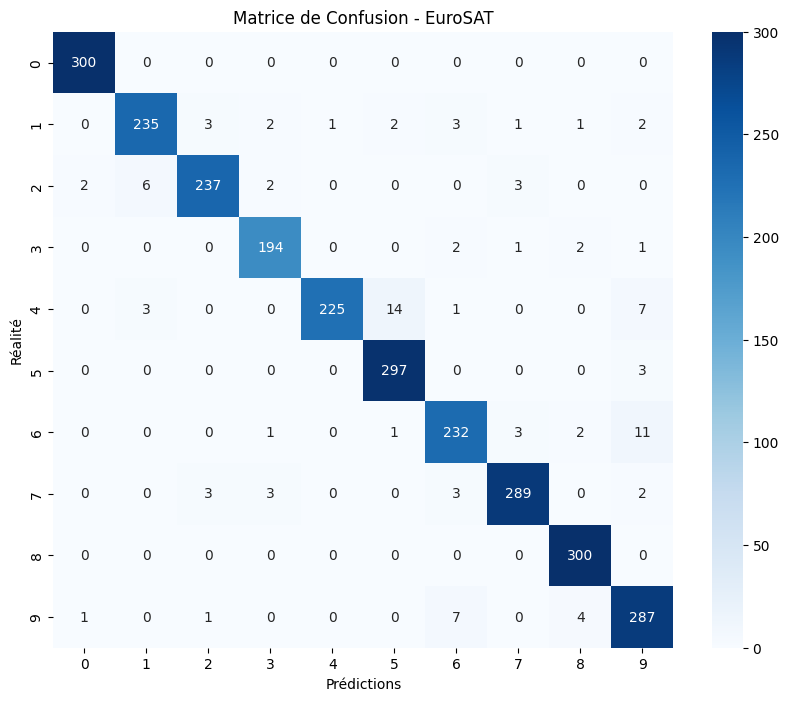

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Prédire les classes pour le set de Test
y_pred = model_custom.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

# 2. Créer la matrice
cm = confusion_matrix(y_true, y_pred_classes)

# 3. Afficher avec Seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Prédictions')
plt.ylabel('Réalité')
plt.title('Matrice de Confusion - EuroSAT')
plt.show()

Cette matrice de confusion pour le jeu de données EuroSAT démontre une excellente performance globale du modèle de classification. La forte concentration des valeurs sur la diagonale principale confirme que la grande majorité des images sont correctement identifiées, avec des résultats parfaits (300/300) pour les classes 0 (Industriel) et 8 (Pâturage). Quelques confusions mineures subsistent, notamment entre les classes 4 (Rivière) et 5 (Mer & Lac) avec 14 erreurs, ainsi qu'entre la végétation (6) et la forêt (9), ce qui suggère des similarités visuelles entre ces catégories. Globalement, le modèle est très robuste, la classe 3 (Cultures permanentes) étant la seule à présenter un score légèrement plus faible avec 194 prédictions correctes.

In [ ]:
import tensorflow as tf
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (224, 224))   # resize image par image
    image = preprocess_input(image)              # prétraitement VGG16
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.shuffle(10000).map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout

# 1. Charger ResNet50 sans la couche de classification finale (top=False)
base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(64, 64, 3))

# 2. Geler les couches de base (on ne réentraîne pas tout au début)
base_model.trainable = False

# 3. Ajouter votre propre "tête" de classification
x = base_model.output
x = GlobalAveragePooling2D()(x) # Remplace le Flatten pour ResNet
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(10, activation='softmax')(x)

# 4. Créer le modèle final
model_resnet = Model(inputs=base_model.input, outputs=predictions)

model_resnet.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


In [ ]:
# 1. Dégeler toutes les couches

base_model.trainable = True

# 2. Re-compiler avec un Learning Rate TRÈS FAIBLE
# C'est CRUCIAL pour ne pas détruire les poids pré-entraînés
from tensorflow.keras.optimizers import Adam
model_resnet.compile(
    optimizer=Adam(learning_rate=1e-5), # 100x plus petit que la normale
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Relancer l'entraînement pour 10-15 époques
history_fine = model_resnet.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stop, lr_reducer]
)

Epoch 1/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 129s 111ms/step - accuracy: 0.4812 - loss: 1.7553 - val_accuracy: 0.1770 - val_loss: 12.5167 - learning_rate: 1.0000e-05
Epoch 2/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 39s 57ms/step - accuracy: 0.8095 - loss: 0.6115 - val_accuracy: 0.9102 - val_loss: 0.2874 - learning_rate: 1.0000e-05
Epoch 3/15
675/676 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.8751 - loss: 0.4115
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757505e-06.
676/676 ━━━━━━━━━━━━━━━━━━━━ 38s 56ms/step - accuracy: 0.8801 - loss: 0.3905 - val_accuracy: 0.9416 - val_loss: 0.1886 - learning_rate: 1.0000e-05
Epoch 4/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 38s 57ms/step - accuracy: 0.9043 - loss: 0.2994 - val_accuracy: 0.9439 - val_loss: 0.1803 - learning_rate: 2.0000e-06
Epoch 5/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 39s 57ms/step - accuracy: 0.9121 - loss: 0.2848 - val_accuracy: 0.9450 - val_loss: 0.1720 - learning_rate: 2.0000e-06
Epoch 6/15
676/676 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step -

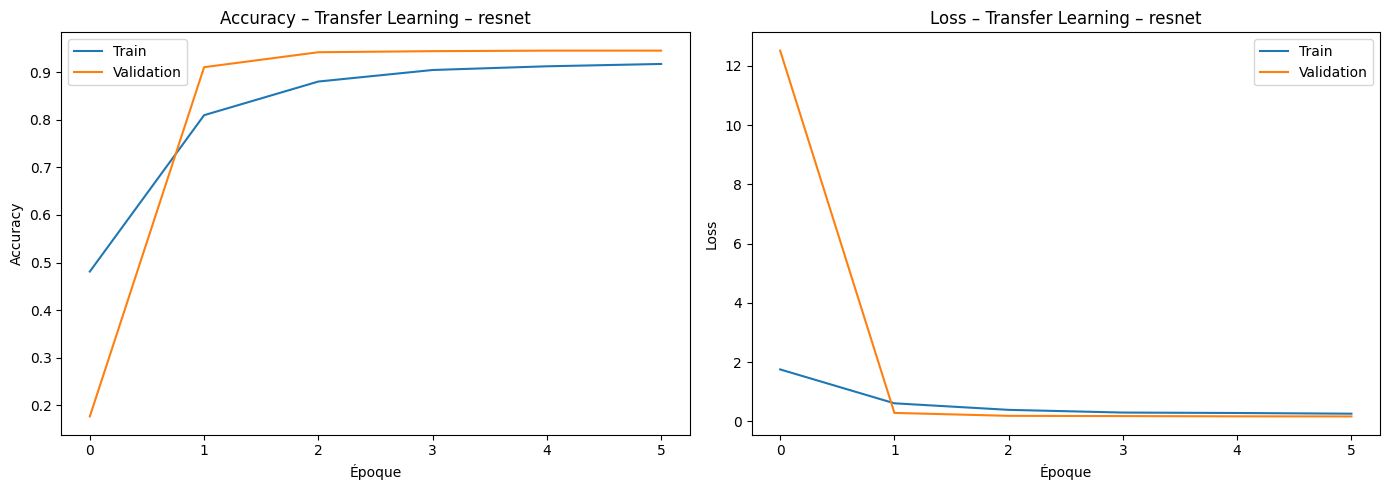

In [ ]:
# Courbes d'apprentissage – Baseline
def plot_history(history, title=''):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(history_fine.history['accuracy'], label='Train')
    axes[0].plot(history_fine.history['val_accuracy'], label='Validation')
    axes[0].set_title(f'Accuracy – {title}')
    axes[0].set_xlabel('Époque')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()

    axes[1].plot(history_fine.history['loss'], label='Train')
    axes[1].plot(history_fine.history['val_loss'], label='Validation')
    axes[1].set_title(f'Loss – {title}')
    axes[1].set_xlabel('Époque')
    axes[1].set_ylabel('Loss')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

plot_history(history_fine, 'Transfer Learning – resnet')


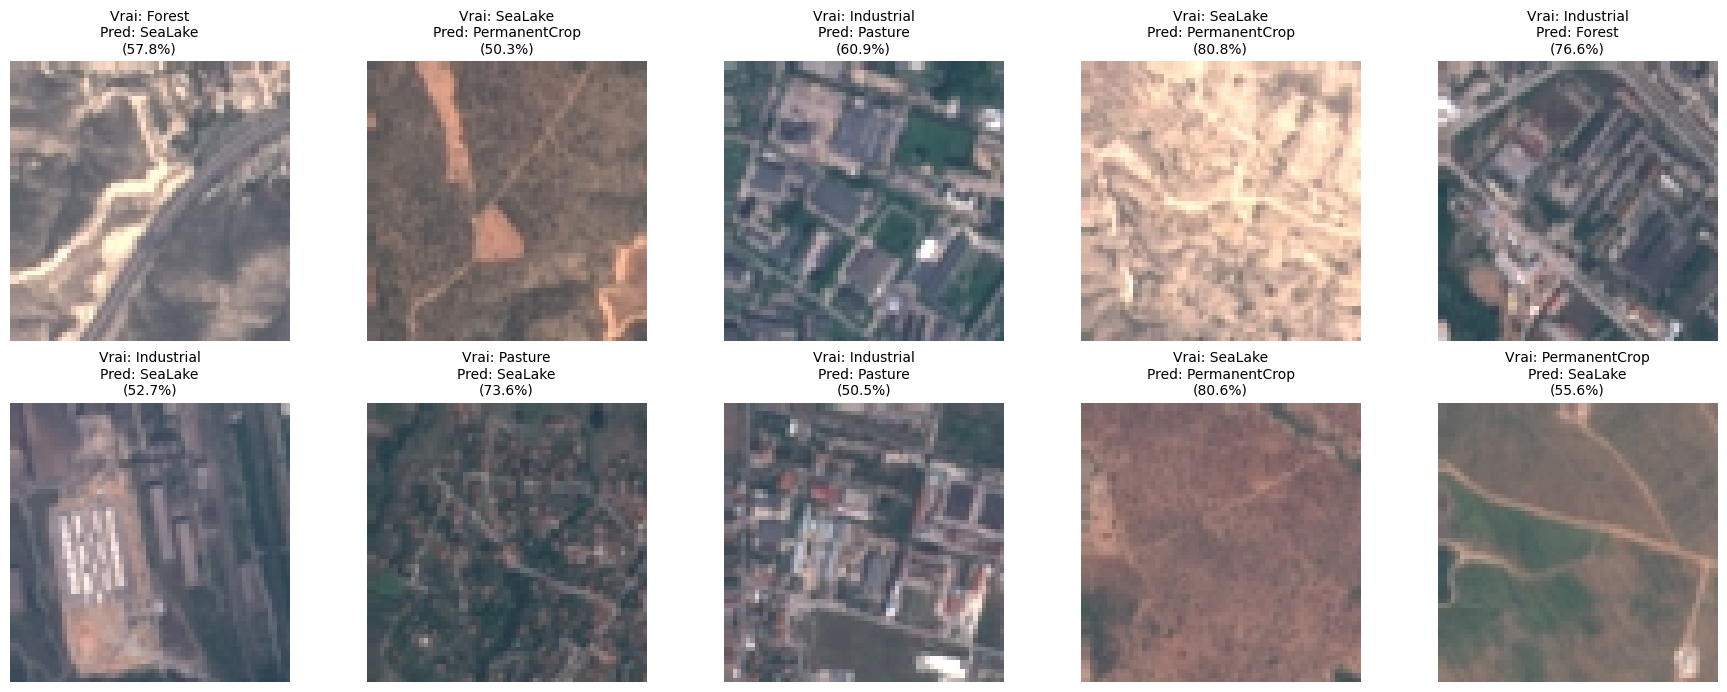

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Définition des labels EuroSAT (ordre standard)
class_names = ['AnnualCrop', 'Forest', 'HerbaceousVeg', 'Highway', 'Industrial',
               'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

# 2. Identification des erreurs
# On compare les classes prédites aux vraies classes
errors = (y_pred_classes != y_true)

# 3. Extraction des données erronées
error_images = X_test[errors]
error_true_labels = y_true[errors]
error_pred_labels = y_pred_classes[errors]

# Extraction des probabilités : on prend le score de la classe que le modèle a choisie à tort
# y_pred[errors] donne les probabilités des échantillons faux
# range(len(...)) avec error_pred_labels permet de cibler la colonne de l'erreur
error_probs = y_pred[errors][np.arange(len(error_pred_labels)), error_pred_labels]

# 4. Affichage des 10 premières erreurs avec labels textuels
plt.figure(figsize=(18, 7))
num_to_plot = min(10, len(error_images))

for i in range(num_to_plot):
    plt.subplot(2, 5, i + 1)
    plt.imshow(error_images[i])

    # Récupération des noms via la liste class_names
    vrai_nom = class_names[error_true_labels[i]]
    pred_nom = class_names[error_pred_labels[i]]
    confiance = error_probs[i]

    plt.title(f"Vrai: {vrai_nom}\nPred: {pred_nom}\n({confiance:.1%})",
              color='black', fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

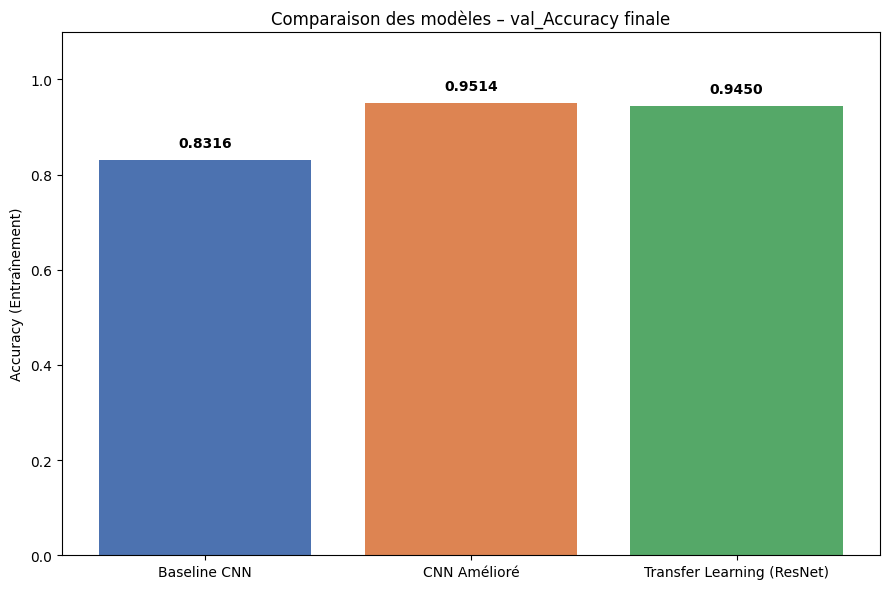

Baseline CNN         : 0.8316
CNN Amélioré         : 0.9514
Transfer Learning    : 0.9450


In [ ]:
import matplotlib.pyplot as plt

# Extraction de la dernière précision (accuracy) enregistrée pour chaque modèle
# On utilise [-1] pour récupérer la valeur de la dernière époque
acc_base = history_base.history['val_accuracy'][-1]
acc_ameliore = history.history['val_accuracy'][-1]
acc_resnet = history_fine.history['val_accuracy'][-1]

modeles = ['Baseline CNN', 'CNN Amélioré', 'Transfer Learning (ResNet)']
accuracies = [acc_base, acc_ameliore, acc_resnet]

plt.figure(figsize=(9, 6))
bars = plt.bar(modeles, accuracies, color=['#4C72B0', '#DD8452', '#55A868'])

plt.ylim(0, 1.1) # Un peu plus de marge pour le texte au-dessus des barres
plt.ylabel('Accuracy (Entraînement)')
plt.title('Comparaison des modèles – val_Accuracy finale')

# Ajout des étiquettes de score au-dessus de chaque barre
for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{acc:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

print(f'Baseline CNN         : {acc_base:.4f}')
print(f'CNN Amélioré         : {acc_ameliore:.4f}')
print(f'Transfer Learning    : {acc_resnet:.4f}')

comparaison entre détaillée entre le CNN Amélioré et le Transfer Learning (ResNet)
## 1. Performance Brute (Accuracy)

* CNN Amélioré (95.14%) : Il l'emporte de peu. C'est impressionnant car cela signifie que l'architecture personnalisée est parfaitement "spécialisée" pour mon dataset.
* ResNet (94.50%) : Très proche, mais légèrement en dessous. C'est un modèle "généraliste" qui a été réadapté.

## 2. Vitesse d'Apprentissage (Convergence)

* ResNet est le plus rapide : Il atteint 90% d'accuracy dès l'époque 1. Grâce à son pré-entraînement sur ImageNet, il "connaît" déjà les formes et les textures. Il n'a eu besoin que de 5 époques pour stabiliser son score.
* CNN Amélioré est plus lent : Il a eu besoin de 35 époques pour atteindre son maximum. Il a dû tout apprendre de zéro (les lignes, les couleurs, puis les objets).

## 3. Stabilité et Fiabilité

* ResNet est plus stable : Ses courbes sont lisses et nettes dès le début. Il n'a montré aucune hésitation.
* CNN Amélioré est plus instable au début : On a vu de fortes oscillations (pics de loss) entre les époques 0 et 8. Cela montre que le modèle a "cherché" sa voie avant de se stabiliser.

## 4. Poids et Ressources

* CNN Amélioré : Probablement beaucoup plus léger en termes de nombre de paramètres et de mémoire (plus facile à utiliser sur un smartphone ou un petit serveur).
* ResNet : C'est un "poids lourd". Il contient des dizaines de couches et des millions de paramètres, ce qui le rend plus lent à l'inférence (prédiction).



